# 02 — EDA de los datasets

Análisis exploratorio de **Real Life Violence Situations** y de **RWF-2000** (el
dataset principal del plan). Responde, antes de entrenar:

1. ¿Cuántos videos hay por clase y están todos sanos?
2. ¿Qué duración, fps y resolución tienen? ¿Son uniformes?
3. ¿Hay diferencias entre clases que el modelo pueda aprender por error
   (atajos) en vez de aprender el comportamiento?

Los metadatos se leen con `src/preprocessing/dataset_metadata.py` (solo
cabeceras de video, no se decodifica el clip completo). Si una carpeta de
dataset no existe en la máquina, esa parte se omite.

**Rutas esperadas** (la carpeta `data/raw/` no se versiona; ver `data/README.md`):

- `data/raw/real_life/{Violence,NonViolence}/`
- `data/raw/rwf2000/{train,val}/{Train_Fight,Train_NonFight,Val_Fight,Val_NonFight}/`

## 1. Imports y configuración

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# El notebook vive en notebooks/, asi que la raiz del repo es el padre.
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.preprocessing.dataset_metadata import scan_dataset, threshold_shortcut

REAL_LIFE_DIR = ROOT / "data" / "raw" / "real_life"
RWF_DIR = ROOT / "data" / "raw" / "rwf2000"
CACHE_DIR = ROOT / "data" / "processed"  # ignorada por git
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Colores fijos por clase para que todas las figuras sean consistentes.
COLORES = {"violencia": "#d1495b", "no_violencia": "#2e86ab"}
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

## 2. Carga de metadatos

Escanear los videos tarda unos segundos (Real Life) a unos minutos (RWF-2000,
~12 GB), así que el resultado se guarda en un CSV en `data/processed/` (no
versionado) y se reutiliza. Borrar el CSV fuerza un nuevo escaneo.

In [2]:
def cargar(nombre: str, carpeta: Path) -> pd.DataFrame:
    """Devuelve los metadatos de un dataset, usando cache en CSV si existe."""
    if not carpeta.exists():
        print(f"[{nombre}] carpeta no encontrada: {carpeta.relative_to(ROOT)} -> se omite")
        return pd.DataFrame()
    cache = CACHE_DIR / f"metadata_{nombre}.csv"
    if cache.exists():
        return pd.read_csv(cache, keep_default_na=False)
    df = scan_dataset(carpeta, nombre)
    df.to_csv(cache, index=False)
    return df


real = cargar("real_life", REAL_LIFE_DIR)
rwf = cargar("rwf2000", RWF_DIR)
meta = pd.concat([d for d in (real, rwf) if len(d)], ignore_index=True)

# Columnas derivadas usadas mas abajo.
meta["resolucion"] = meta["ancho"].astype(str) + "x" + meta["alto"].astype(str)
meta["pixeles"] = meta["ancho"] * meta["alto"]
# Bitrate aproximado: delata el nivel de compresion del video.
meta["bitrate_kbps"] = np.where(meta["segundos"] > 0,
                                meta["bytes"] * 8 / meta["segundos"].where(meta["segundos"] > 0, 1) / 1000, 0.0)
meta["es_violencia"] = (meta["clase"] == "violencia").astype(int)

DATASETS = list(meta["dataset"].unique())
print(meta.groupby("dataset").size().to_string())
# La columna "ruta" (ruta absoluta local) no se muestra para no filtrarla
# en la salida del notebook que se sube al repo.
meta.drop(columns="ruta").head()

dataset
real_life    2000
rwf2000      2000


,dataset,split,clase,archivo,formato,bytes,frames,fps,ancho,alto,legible,segundos,resolucion,pixeles,bitrate_kbps,es_violencia
0,real_life,,no_violencia,NV_1.mp4,mp4,7982710,66,24.900440,1920,1080,True,2.650556,1920x1080,2073600,24093.696080,0
1,real_life,,no_violencia,NV_10.mp4,mp4,1151518,150,30.000000,224,224,True,5.000000,224x224,50176,1842.428800,0
2,real_life,,no_violencia,NV_100.mp4,mp4,1588682,150,30.000000,224,224,True,5.000000,224x224,50176,2541.891200,0
3,real_life,,no_violencia,NV_1000.mp4,mp4,519064,104,23.976024,1280,720,True,4.337667,1280x720,921600,957.314685,0
4,real_life,,no_violencia,NV_101.mp4,mp4,1021964,150,30.000000,224,224,True,5.000000,224x224,50176,1635.142400,0


## 3. Integridad y distribución de clases

Si hubiera clases muy desbalanceadas habría que ponderar la pérdida o
usar métricas por clase; por eso se mira antes de entrenar.

Ilegibles: 0
Con 0 bytes: 0
clase      no_violencia  violencia
dataset                           
real_life          1000       1000
rwf2000            1000       1000


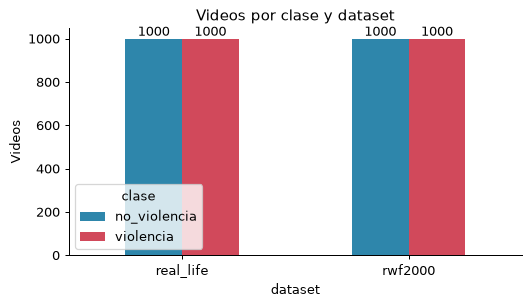

In [3]:
# Videos que OpenCV no logra leer (deberian ser 0).
print("Ilegibles:", int((~meta["legible"].astype(bool)).sum()))
print("Con 0 bytes:", int((meta["bytes"] == 0).sum()))

conteo = meta.groupby(["dataset", "clase"]).size().unstack(fill_value=0)
print(conteo.to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
conteo.plot.bar(ax=ax, color=[COLORES[c] for c in conteo.columns], rot=0)
ax.set_ylabel("Videos")
ax.set_title("Videos por clase y dataset")
for cont in ax.containers:
    ax.bar_label(cont)
plt.tight_layout()
plt.show()

## 4. Duración de los clips

El pipeline toma 16 frames **espaciados uniformemente** de todo el clip. En un clip
de 5 s eso es un frame cada ~0,33 s, pero en uno de varios minutos cada frame
quedaría a decenas de segundos del anterior y el movimiento corto se perdería.
Cada fila de la figura es un dataset (no se mezclan).

                         count  mean    std  min  50%   95%     max
dataset   clase                                                    
real_life no_violencia  1000.0   5.1   5.55  1.0  5.0  5.34  179.90
          violencia     1000.0   5.4  12.46  2.9  5.0  5.90  375.73
rwf2000   no_violencia  1000.0   5.0   0.00  5.0  5.0  5.00    5.00
          violencia     1000.0   5.0   0.00  5.0  5.0  5.00    5.00


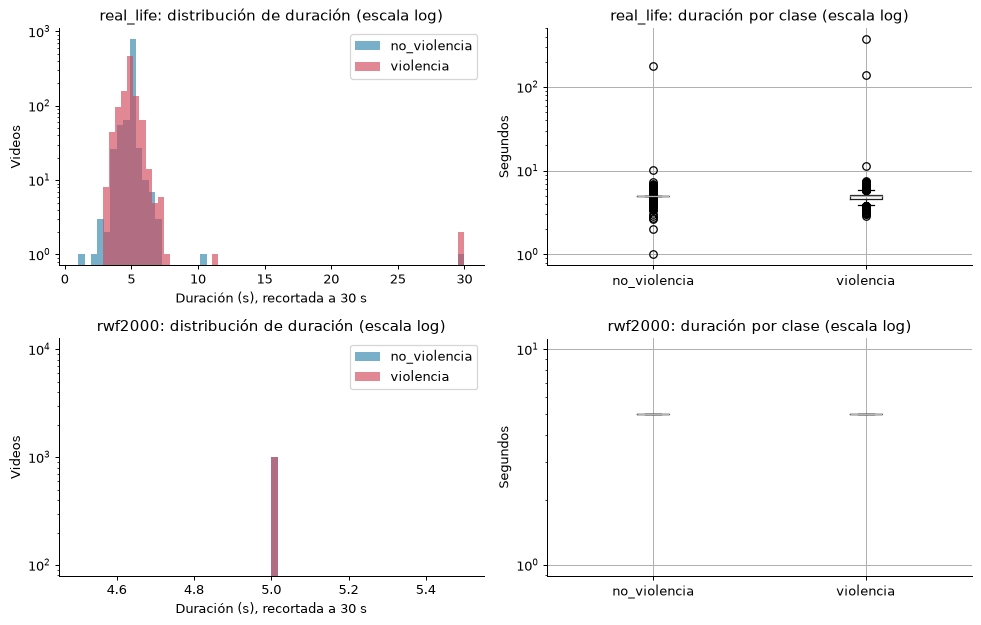


Clips de más de 30 s: 3
  dataset        clase    archivo   segundos
real_life    violencia  V_789.mp4 375.733333
real_life no_violencia NV_992.mp4 179.900000
real_life    violencia  V_398.mp4 136.966667


In [4]:
resumen = meta.groupby(["dataset", "clase"])["segundos"].describe(
    percentiles=[0.5, 0.95]).round(2)
print(resumen.to_string())

fig, ejes = plt.subplots(len(DATASETS), 2, figsize=(11, 3.6 * len(DATASETS)), squeeze=False)
for fila, ds in enumerate(DATASETS):
    d = meta[meta["dataset"] == ds]
    for clase, g in d.groupby("clase"):
        # Se recorta a 30 s para ver donde esta la masa de datos.
        ejes[fila][0].hist(g["segundos"].clip(upper=30), bins=60, alpha=0.65,
                           color=COLORES[clase], label=clase)
    ejes[fila][0].set_xlabel("Duración (s), recortada a 30 s")
    ejes[fila][0].set_ylabel("Videos")
    ejes[fila][0].set_yscale("log")
    ejes[fila][0].legend()
    ejes[fila][0].set_title(f"{ds}: distribución de duración (escala log)")

    d.boxplot(column="segundos", by="clase", ax=ejes[fila][1], showfliers=True)
    ejes[fila][1].set_yscale("log")
    ejes[fila][1].set_title(f"{ds}: duración por clase (escala log)")
    ejes[fila][1].set_xlabel("")
    ejes[fila][1].set_ylabel("Segundos")
plt.suptitle("")
plt.tight_layout()
plt.show()

largos = meta[meta["segundos"] > 30][["dataset", "clase", "archivo", "segundos"]]
print(f"\nClips de más de 30 s: {len(largos)}")
print(largos.sort_values("segundos", ascending=False).to_string(index=False))

## 5. FPS, resolución y formato

Las diferencias de fps cambian cuánto tiempo real cubre cada salto entre frames
muestreados; las de resolución importan porque todo se reescala a 224×224.

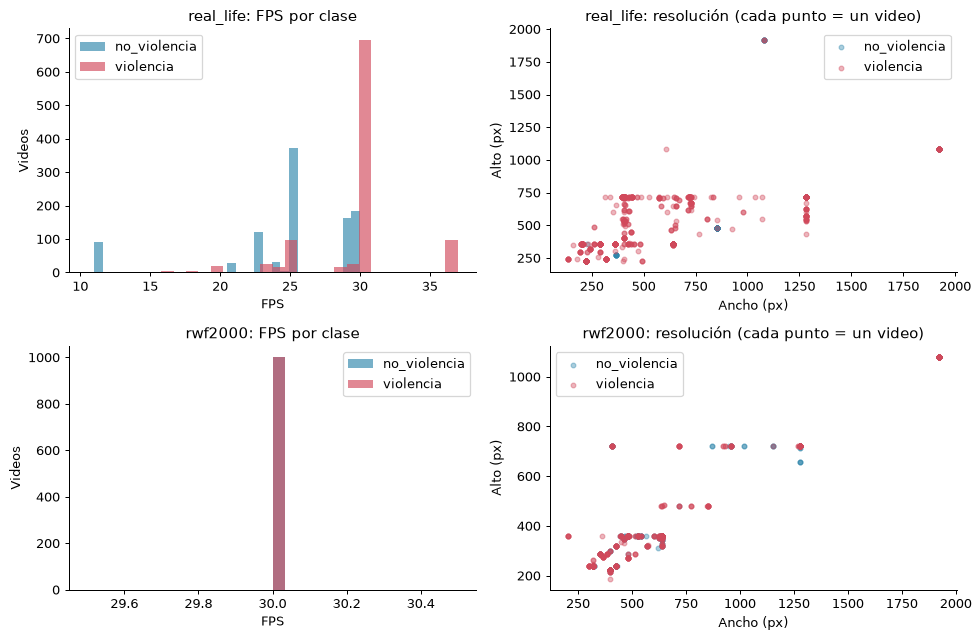

  dataset        clase resolucion  videos
real_life no_violencia    224x224     749
real_life no_violencia   1280x720     115
real_life no_violencia    640x360      79
real_life no_violencia    854x480      35
real_life    violencia    224x224     199
real_life    violencia   1280x720     164
real_life    violencia    640x360     114
real_life    violencia    360x360      49
  rwf2000 no_violencia    320x240     566
  rwf2000 no_violencia   1280x720     232
  rwf2000 no_violencia    640x360      44
  rwf2000 no_violencia    480x360      32
  rwf2000    violencia   1280x720     396
  rwf2000    violencia    320x240     134
  rwf2000    violencia    640x360     125
  rwf2000    violencia    480x360      57

dataset    clase         formato
real_life  no_violencia  avi          49
                         mp4         951
           violencia     mp4        1000
rwf2000    no_violencia  avi        1000
           violencia     avi        1000


In [5]:
fig, ejes = plt.subplots(len(DATASETS), 2, figsize=(11, 3.6 * len(DATASETS)), squeeze=False)
for fila, ds in enumerate(DATASETS):
    d = meta[meta["dataset"] == ds]
    for clase, g in d.groupby("clase"):
        ejes[fila][0].hist(g["fps"], bins=30, alpha=0.65, color=COLORES[clase], label=clase)
        ejes[fila][1].scatter(g["ancho"], g["alto"], s=14, alpha=0.4,
                              color=COLORES[clase], label=clase)
    ejes[fila][0].set_xlabel("FPS")
    ejes[fila][0].set_ylabel("Videos")
    ejes[fila][0].legend()
    ejes[fila][0].set_title(f"{ds}: FPS por clase")
    ejes[fila][1].set_xlabel("Ancho (px)")
    ejes[fila][1].set_ylabel("Alto (px)")
    ejes[fila][1].legend()
    ejes[fila][1].set_title(f"{ds}: resolución (cada punto = un video)")
plt.tight_layout()
plt.show()

top = (meta.groupby(["dataset", "clase", "resolucion"]).size()
       .rename("videos").reset_index()
       .sort_values(["dataset", "clase", "videos"], ascending=[True, True, False])
       .groupby(["dataset", "clase"]).head(4))
print(top.to_string(index=False))
print()
print(meta.groupby(["dataset", "clase", "formato"]).size().to_string())

## 6. Posible atajo: ¿características que no son el comportamiento delatan la clase?

Si una característica **que no es el comportamiento** (resolución, fps,
compresión) separa las clases, un modelo puede aprenderla en lugar de la pelea.

Se mide con la regla más simple posible: **una sola característica y un umbral**.
Para no sobreestimar, el umbral se elige en un conjunto y se evalúa en otro:

- **RWF-2000:** umbral elegido en `train` y evaluado en `val` (split original).
- **Real Life:** no trae split; se usa una mitad al azar (semilla 42) para elegir y la otra para evaluar.

Un resultado cercano a 50 % significa que la característica **no** delata la clase.

  dataset     evaluacion caracteristica                              regla  exactitud_test
real_life mitad -> mitad            fps            violencia si fps > 29.4           0.813
real_life mitad -> mitad          ancho         violencia si ancho > 226.0           0.737
real_life mitad -> mitad           alto          violencia si alto > 232.0           0.770
real_life mitad -> mitad        pixeles     violencia si pixeles > 53438.0           0.767
real_life mitad -> mitad       segundos        violencia si segundos > 5.0           0.629
real_life mitad -> mitad   bitrate_kbps violencia si bitrate_kbps > 1390.8           0.545
  rwf2000   train -> val            fps            violencia si fps > 30.0           0.500
  rwf2000   train -> val          ancho         violencia si ancho > 337.0           0.748
  rwf2000   train -> val           alto          violencia si alto > 251.0           0.750
  rwf2000   train -> val        pixeles     violencia si pixeles > 80560.0           0.748

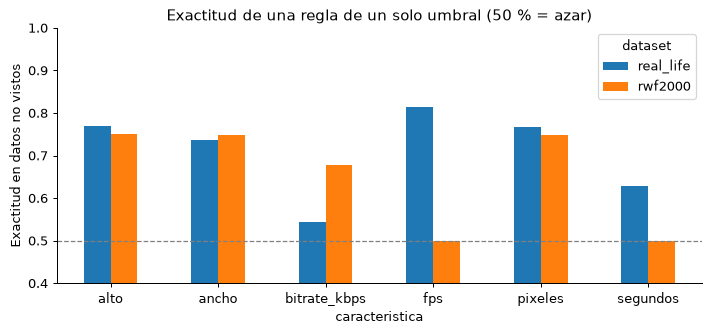

In [6]:
CARACTERISTICAS = ["fps", "ancho", "alto", "pixeles", "segundos", "bitrate_kbps"]
filas = []
for ds in DATASETS:
    d = meta[meta["dataset"] == ds]
    if (d["split"] != "").any():
        tr, te = d[d["split"] == "train"], d[d["split"] == "val"]
        origen = "train -> val"
    else:
        tr = d.sample(frac=0.5, random_state=42)
        te = d.drop(tr.index)
        origen = "mitad -> mitad"
    for car in CARACTERISTICAS:
        r = threshold_shortcut(tr[car], tr["es_violencia"], te[car], te["es_violencia"])
        filas.append({"dataset": ds, "evaluacion": origen, "caracteristica": car,
                      "regla": f"violencia si {car} {r['sentido']} {r['umbral']:.1f}",
                      "exactitud_test": round(r["acc_test"], 3)})
atajos = pd.DataFrame(filas)
print(atajos.to_string(index=False))

pivote = atajos.pivot(index="caracteristica", columns="dataset", values="exactitud_test")
ax = pivote.plot.bar(figsize=(8, 3.8), rot=0)
ax.axhline(0.5, color="gray", ls="--", lw=1)
ax.set_ylabel("Exactitud en datos no vistos")
ax.set_ylim(0.4, 1)
ax.set_title("Exactitud de una regla de un solo umbral (50 % = azar)")
plt.tight_layout()
plt.show()

In [7]:
# Regla concreta de Real Life: "si mide exactamente 224x224 -> no violencia".
rl = meta[meta["dataset"] == "real_life"]
if len(rl):
    es_224 = (rl["ancho"] == 224) & (rl["alto"] == 224)
    print(pd.crosstab(rl["clase"], es_224.map({True: "224x224", False: "otra resolución"})).to_string())
    pred = np.where(es_224, "no_violencia", "violencia")
    print(f"\nExactitud de la regla solo con la resolución (sobre los 2000 videos): {(pred == rl['clase']).mean():.1%}")

col_0         224x224  otra resolución
clase                                 
no_violencia      749              251
violencia         199              801

Exactitud de la regla solo con la resolución (sobre los 2000 videos): 77.5%


## 7. Muestra visual

Frame central de 5 videos aleatorios por clase y dataset (semilla fija). Sirve
para comprobar a ojo qué hay en cada clase y qué tan distinta es la calidad.

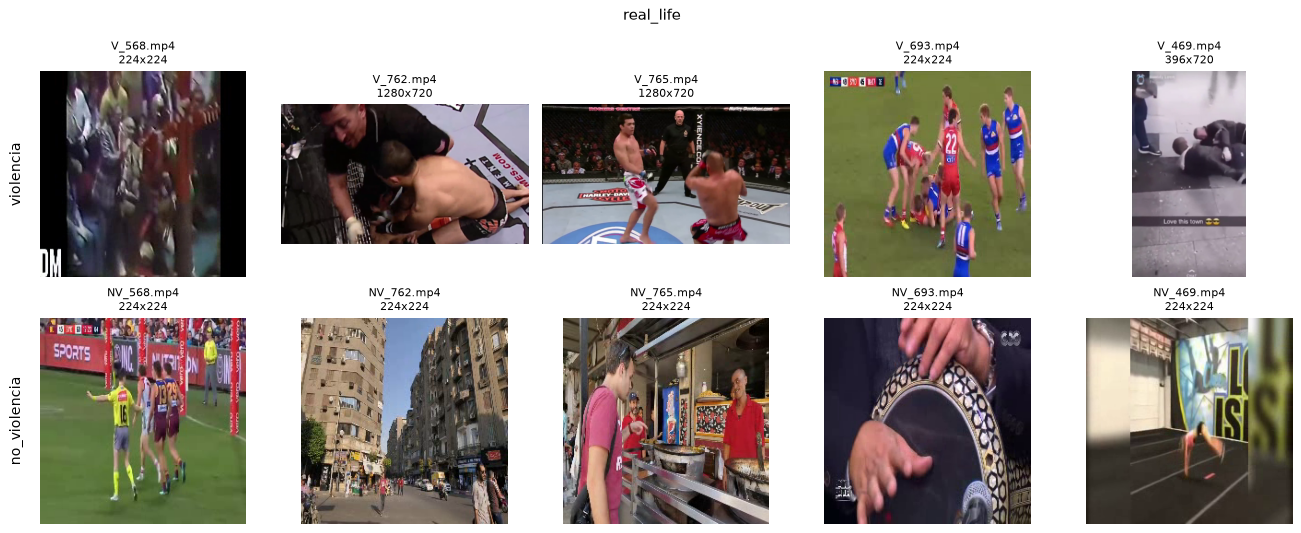

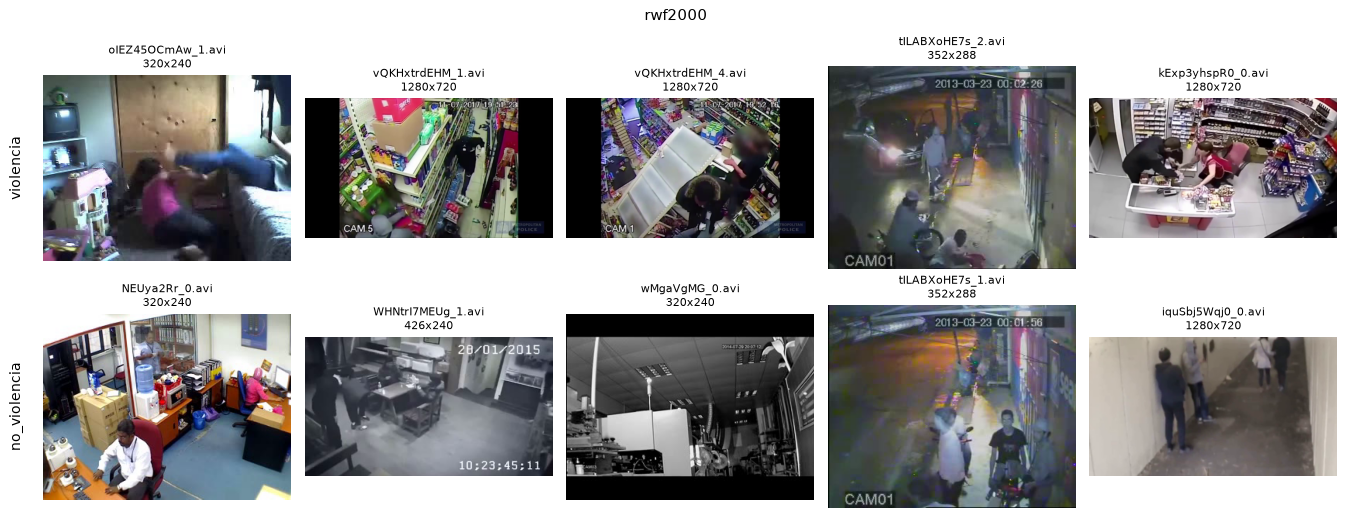

In [8]:
def frame_central(ruta: str) -> np.ndarray:
    """Devuelve el frame del medio del video en RGB."""
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if ok else np.zeros((224, 224, 3), np.uint8)


N = 5
for ds in DATASETS:
    d = meta[meta["dataset"] == ds]
    fig, ejes = plt.subplots(2, N, figsize=(3 * N, 6))
    for fila, clase in enumerate(["violencia", "no_violencia"]):
        muestra = d[d["clase"] == clase].sample(N, random_state=42)
        for ax, (_, v) in zip(ejes[fila], muestra.iterrows()):
            ax.imshow(frame_central(v["ruta"]))
            ax.set_title(f"{v['archivo'][:18]}\n{v['ancho']}x{v['alto']}", fontsize=9)
            ax.axis("off")
        ejes[fila][0].text(-0.08, 0.5, clase, transform=ejes[fila][0].transAxes,
                           rotation=90, va="center", ha="right", fontsize=11)
    fig.suptitle(ds)
    plt.tight_layout()
    plt.show()

## 8. RWF-2000: contraste con lo informado por el equipo

El equipo registró 2000 clips de 5 s a 30 fps (MJPEG): 800 + 800 en `train` y
200 + 200 en `val`. Aquí se contrasta con lo que realmente se lee de los archivos.

In [9]:
if len(rwf):
    print(rwf.groupby(["split", "clase"]).size().unstack(fill_value=0).to_string())
    print()
    print(rwf.groupby("clase")[["segundos", "fps", "ancho", "alto"]].describe().T.round(2).to_string())
    print("\nResoluciones distintas:", rwf.groupby(["ancho", "alto"]).size().to_dict())
    print("FPS distintos:", rwf["fps"].round(2).value_counts().to_dict())
    print("Ilegibles:", int((~rwf["legible"].astype(bool)).sum()))
else:
    print("RWF-2000 no está en esta máquina: descargarlo del Drive a data/raw/rwf2000/ "
          "y volver a ejecutar el notebook.")

clase  no_violencia  violencia
split                         
train           800        800
val             200        200

clase           no_violencia  violencia
segundos count       1000.00    1000.00
         mean           5.00       5.00
         std            0.00       0.00
         min            5.00       5.00
         25%            5.00       5.00
         50%            5.00       5.00
         75%            5.00       5.00
         max            5.00       5.00
fps      count       1000.00    1000.00
         mean          30.00      30.00
         std            0.00       0.00
         min           30.00      30.00
         25%           30.00      30.00
         50%           30.00      30.00
         75%           30.00      30.00
         max           30.00      30.00
ancho    count       1000.00    1000.00
         mean         607.39     841.10
         std          417.78     430.09
         min          320.00     204.00
         25%          320.00     46

### Clips que vienen del mismo video original

Los nombres de RWF-2000 siguen el patrón `<id_del_video>_<n>.avi`: varios clips
salen de un mismo video. Si clips del mismo video cayeran en `train` y en `val`,
la validación sería demasiado optimista (el modelo "reconocería" la escena).
Se agrupa por el prefijo del nombre como **aproximación** a la fuente (no hay
metadato oficial de fuente).

In [10]:
if len(rwf):
    rwf = rwf.copy()
    rwf["fuente"] = rwf["archivo"].str.rsplit("_", n=1).str[0]
    g = rwf.groupby("fuente").agg(clips=("archivo", "size"),
                                  splits=("split", "nunique"),
                                  clases=("clase", "nunique"))
    print("Clips:", len(rwf), "| videos fuente distintos (aprox.):", rwf["fuente"].nunique())
    print("Fuentes con más de 1 clip:", int((g["clips"] > 1).sum()),
          "| clips en ellas:", int(g.loc[g["clips"] > 1, "clips"].sum()))
    print("Fuentes presentes en train Y val:", int((g["splits"] > 1).sum()))
    print("Fuentes con clips de AMBAS clases:", int((g["clases"] > 1).sum()))
    print("Clips por fuente (distribución):", g["clips"].value_counts().sort_index().to_dict())

Clips: 2000 | videos fuente distintos (aprox.): 961
Fuentes con más de 1 clip: 311 | clips en ellas: 1350
Fuentes presentes en train Y val: 0
Fuentes con clips de AMBAS clases: 150
Clips por fuente (distribución): {1: 650, 2: 94, 3: 51, 4: 53, 5: 31, 6: 28, 7: 23, 8: 8, 9: 9, 10: 6, 11: 3, 12: 2, 13: 1, 16: 1, 22: 1}


## 9. Conclusiones

Todo sale de las tablas y figuras de arriba (2000 videos por dataset).

**Integridad y balance**
- Real Life y RWF-2000: 1000 videos por clase, 0 ilegibles, 0 vacíos. No hace
  falta ponderar clases. Los conteos de RWF-2000 coinciden con lo informado por el
  equipo (800/800 en `train`, 200/200 en `val`).

**Duración y fps**
- RWF-2000 es uniforme: **todos** los clips duran 5,0 s a 30 fps (formato `.avi`).
  16 frames dan un frame cada ~0,33 s en todos los casos.
- Real Life no lo es: mediana de 5 s, fps entre 10 y 37, y 3 clips de más de 30 s
  (`V_789` ≈ 376 s, `NV_992` ≈ 180 s, `V_398` ≈ 137 s). Con 16 frames uniformes, el de
  ~6 minutos daría un frame cada ~25 s; **hay que decidir en el equipo** si se
  excluyen o se recortan (son 3 de 2000).

**Resolución (ninguno de los dos es uniforme)**
- RWF-2000 **no** es todo de baja resolución: hay 628 clips de 1280×720 y 31 de
  1920×1080, pero la mayoría (700) mide 320×240. Hay varias relaciones de aspecto
  (4:3, 16:9, verticales), así que el resize a 224×224 los deforma distinto.

**Posibles atajos (regla de un solo umbral, evaluada en datos no usados para elegirlo)**
- *Real Life:* el fps separa las clases con 81,3 % de exactitud y la resolución
  con 74–77 %. Parte de lo que un modelo aprendería ahí es origen/calidad del video.
- *RWF-2000:* el fps y la duración **no** delatan la clase (50 %, azar), pero la
  **resolución sí: ~75 %** (los clips de pelea tienden a ser más grandes: 396 de
  `violencia` son 1280×720 contra 232 de `no_violencia`; 566 de `no_violencia` son
  320×240 contra 134). El bitrate llega a 67,7 %.
- Consecuencia: **ni siquiera RWF-2000 está libre de atajos**. No es posible
  concluir que un modelo entrenado en él aprende el comportamiento solo por
  tener buena exactitud; conviene comparar contra estas reglas simples como
  línea base (una regla de resolución ya acierta ~75 %) y revisar los
  errores del modelo según la resolución del clip.

**Fuentes repetidas y fuga entre train y val (RWF-2000)**
- Los 2000 clips salen de ~961 videos fuente (aproximado por el prefijo del
  nombre); 311 fuentes aportan más de un clip (1350 clips). **Ninguna fuente
  aparece a la vez en `train` y en `val`**, por lo que el split original no
  tiene fuga por este criterio. 150 fuentes tienen clips de ambas clases, lo que
  ayuda a que la cámara no delate la clase.
- Implicación: si se crea un conjunto de prueba (test) propio o se hace
  validación cruzada, **hay que dividir por fuente** y no por clip. Real Life no
  trae split ni identificador de fuente: una división al azar puede mezclar
  clips muy parecidos entre conjuntos.

**Contenido (muestra de 5 por clase)**
- Real Life mezcla deportes de contacto y tomas de transmisión; RWF-2000 es
  realmente cámara de vigilancia (tiendas, pasillos, calles, con etiquetas de
  cámara y fecha). Coincide con la limitación del plan sobre deportes y confirma que
  RWF-2000 es el dataset más cercano al caso de uso.

**Limitaciones de este análisis:** son reglas sobre metadatos, no sobre el
contenido; la agrupación por fuente se hizo con el nombre del archivo; y la
muestra visual es de solo 5 clips por clase.

La comparación 8 vs 16 vs 32 frames está en `03_comparar_frames.ipynb`.
